# 01 · Khám phá dữ liệu

Mọi thống kê và hình dưới đây dùng tập train.

Notebook chạy độc lập từ thư mục gốc hoặc `notebooks/`; cài `requirements-demo.txt` trước.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT/'student_success').exists(): ROOT = ROOT.parent
assert (ROOT/'student_success').exists(), 'Chạy từ thư mục dự án hoặc notebooks/'
sys.path.insert(0, str(ROOT))
from student_success.data import CATEGORICAL, NUMERIC, LABELS, SEED, split
DATA = ROOT/'data/raw/data.csv'
assert DATA.exists(), 'Chạy python scripts/download_data.py'
df = pd.read_csv(DATA, sep=';'); df.columns = df.columns.str.strip()
train_idx, test_idx = split(df)
train = df.loc[train_idx]
R = ROOT/'data/experiment'


,Application order,Previous qualification (grade),Admission grade,Age at enrollment
count,3539.000000,3539.000000,3539.000000,3539.000000
mean,1.727042,132.684713,126.876745,23.249506
std,1.307274,13.202248,14.530706,7.605164
min,0.000000,95.000000,95.000000,17.000000
25%,1.000000,125.000000,117.800000,19.000000
50%,1.000000,133.100000,126.000000,20.000000
75%,2.000000,140.000000,134.900000,25.000000
max,9.000000,190.000000,190.000000,70.000000


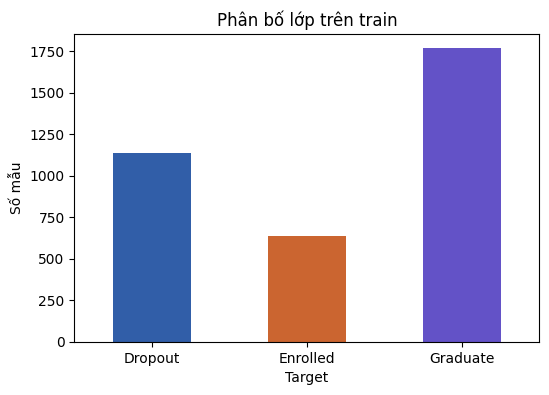

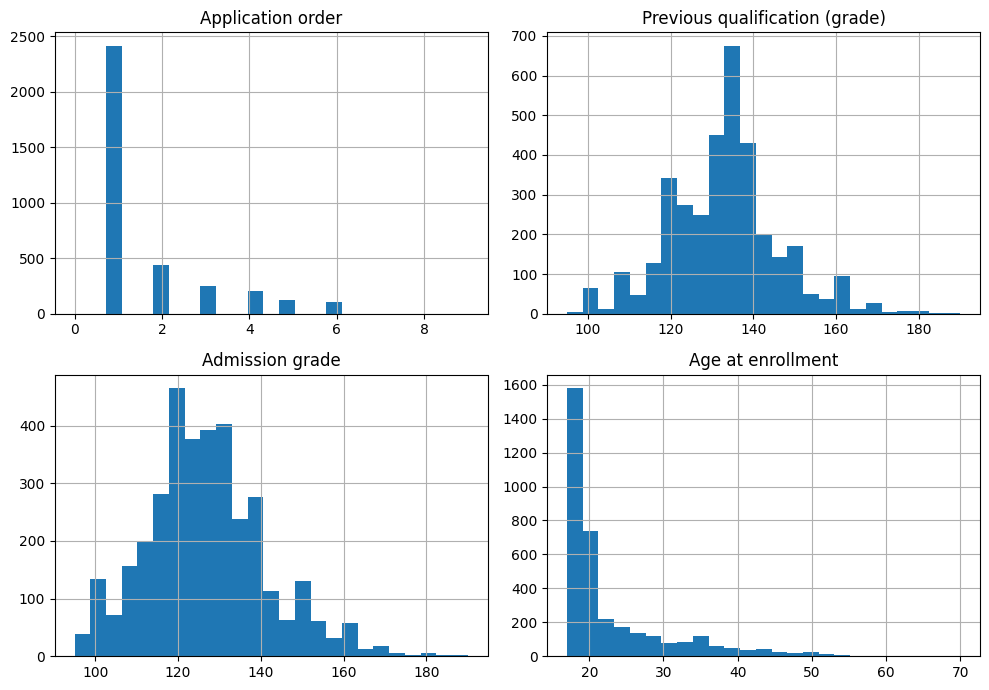

In [2]:
display(train[NUMERIC].describe())
fig, ax = plt.subplots(figsize=(6,4))
train.Target.value_counts().reindex(LABELS).plot.bar(ax=ax, rot=0, color=['#315ea8','#cb6530','#6352c7'])
ax.set(title='Phân bố lớp trên train', ylabel='Số mẫu'); plt.show()
train[NUMERIC].hist(figsize=(10,7), bins=25); plt.tight_layout(); plt.show()

,Application order,Previous qualification (grade),Admission grade,Age at enrollment
Application order,1.000000,-0.064042,-0.092354,-0.270192
Previous qualification (grade),-0.064042,1.000000,0.580981,-0.112140
Admission grade,-0.092354,0.580981,1.000000,-0.019455
Age at enrollment,-0.270192,-0.112140,-0.019455,1.000000


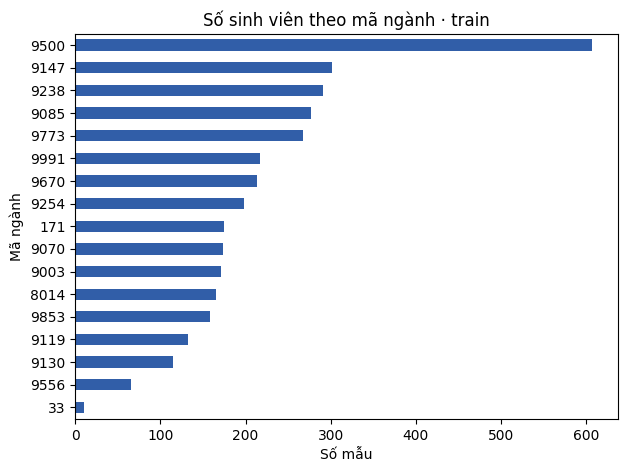

In [3]:
display(train[NUMERIC].corr())
fig,ax=plt.subplots(figsize=(7,5))
train.Course.value_counts().sort_values().plot.barh(ax=ax, color='#315ea8')
ax.set(title='Số sinh viên theo mã ngành · train', xlabel='Số mẫu', ylabel='Mã ngành'); plt.show()